# 04. Modeling & Evaluasi: Support Vector Machine (SVM)
## Pelatihan Model Tunggal SVM (StandardScaler + SVC RBF)

Notebook ini memuat data `output/df_poligon_split.csv`, membangun Pipeline Machine Learning tunggal:
$$\text{Pipeline} = \text{StandardScaler}() + \text{SVC}(\text{kernel}='rbf', C=10, \gamma='scale', \text{probability}=True, \text{random\_state}=42)$$
Melatih model pada 285 poligon latih, mengevaluasi pada 72 poligon uji, menghitung akurasi, Macro F1, Weighted F1, Confusion Matrix, Classification Report, dan menyimpan model ke `output/model_svm.joblib` serta hasil prediksi ke `output/df_poligon_pred_svm.csv`.

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

BASE_DIR = Path.cwd()
OUT_DIR = BASE_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SPLIT_FILE = OUT_DIR / "df_poligon_split.csv"
if not SPLIT_FILE.exists():
    raise FileNotFoundError(
        f"File {SPLIT_FILE} tidak ditemukan! Jalankan notebook '03_data_preparation.ipynb' terlebih dahulu."
    )

print(f"Memuat data poligon dari: {SPLIT_FILE}")
df_poligon = pd.read_csv(SPLIT_FILE)
print(f"Data termuat: {len(df_poligon)} poligon")

Memuat data poligon dari: D:\tugas psd\website-jupyterbook\UTS\output\df_poligon_split.csv
Data termuat: 357 poligon


### 1. Persiapan Matriks Fitur dan Target Latih-Uji

In [2]:
FITUR_SPEKTRAL = ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']
label_names = ['Sawah', 'Bangunan', 'Hutan', 'Danau', 'Laut', 'Mangrove']

train_mask = df_poligon['split'] == 'Train'
test_mask = df_poligon['split'] == 'Test'

X_train = df_poligon.loc[train_mask, FITUR_SPEKTRAL]
y_train = df_poligon.loc[train_mask, 'label']

X_test = df_poligon.loc[test_mask, FITUR_SPEKTRAL]
y_test = df_poligon.loc[test_mask, 'label']

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test : {X_test.shape}, y_test : {y_test.shape}")

X_train: (285, 9), y_train: (285,)
X_test : (72, 9), y_test : (72,)


### 2. Inisialisasi dan Pelatihan Pipeline SVM
Menggunakan parameter terstandarisasi:
- Scaler: `StandardScaler()`
- Classifier: `SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=42)`

In [3]:
model_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=42))
])

print("Melatih pipeline SVM...")
model_pipeline.fit(X_train, y_train)
print("Pelatihan selesai!")

# Menyimpan model terlatih ke output/model_svm.joblib
berkas_model = OUT_DIR / "model_svm.joblib"
joblib.dump(model_pipeline, berkas_model)
print(f"Model SVM tersimpan di: {berkas_model.resolve()}")

Melatih pipeline SVM...
Pelatihan selesai!
Model SVM tersimpan di: D:\tugas psd\website-jupyterbook\UTS\output\model_svm.joblib


D:\tugas psd\website-jupyterbook\.venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


### 3. Evaluasi Kinerja Model pada Data Uji

In [4]:
# Prediksi pada data latih dan uji
y_train_pred = model_pipeline.predict(X_train)
y_test_pred = model_pipeline.predict(X_test)

acc_train = accuracy_score(y_train, y_train_pred) * 100
acc_test = accuracy_score(y_test, y_test_pred) * 100
f1_macro = f1_score(y_test, y_test_pred, average='macro')
f1_weighted = f1_score(y_test, y_test_pred, average='weighted')

print("="*50)
print(f"Akurasi Data Latih (Train) : {acc_train:.2f}%")
print(f"Akurasi Data Uji (Test)    : {acc_test:.2f}%")
print(f"Macro F1-Score (Test)      : {f1_macro:.4f}")
print(f"Weighted F1-Score (Test)   : {f1_weighted:.4f}")
print("="*50)

# Classification Report
target_names_eval = [f"{i}: {name}" for i, name in enumerate(label_names, 1)]
report_str = classification_report(y_test, y_test_pred, target_names=target_names_eval, digits=4)
print("\n=== CLASSIFICATION REPORT DATA UJI ===")
print(report_str)

# Menyimpan classification report ke text
with open(OUT_DIR / "04_classification_report.txt", "w", encoding="utf-8") as f:
    f.write(report_str)

Akurasi Data Latih (Train) : 91.93%
Akurasi Data Uji (Test)    : 88.89%
Macro F1-Score (Test)      : 0.8879
Weighted F1-Score (Test)   : 0.8879

=== CLASSIFICATION REPORT DATA UJI ===
              precision    recall  f1-score   support

    1: Sawah     0.7143    0.8333    0.7692        12
 2: Bangunan     0.8000    1.0000    0.8889        12
    3: Hutan     1.0000    0.6667    0.8000        12
    4: Danau     0.9231    1.0000    0.9600        12
     5: Laut     1.0000    1.0000    1.0000        12
 6: Mangrove     1.0000    0.8333    0.9091        12

    accuracy                         0.8889        72
   macro avg     0.9062    0.8889    0.8879        72
weighted avg     0.9062    0.8889    0.8879        72



### 4. Visualisasi Confusion Matrix Model SVM

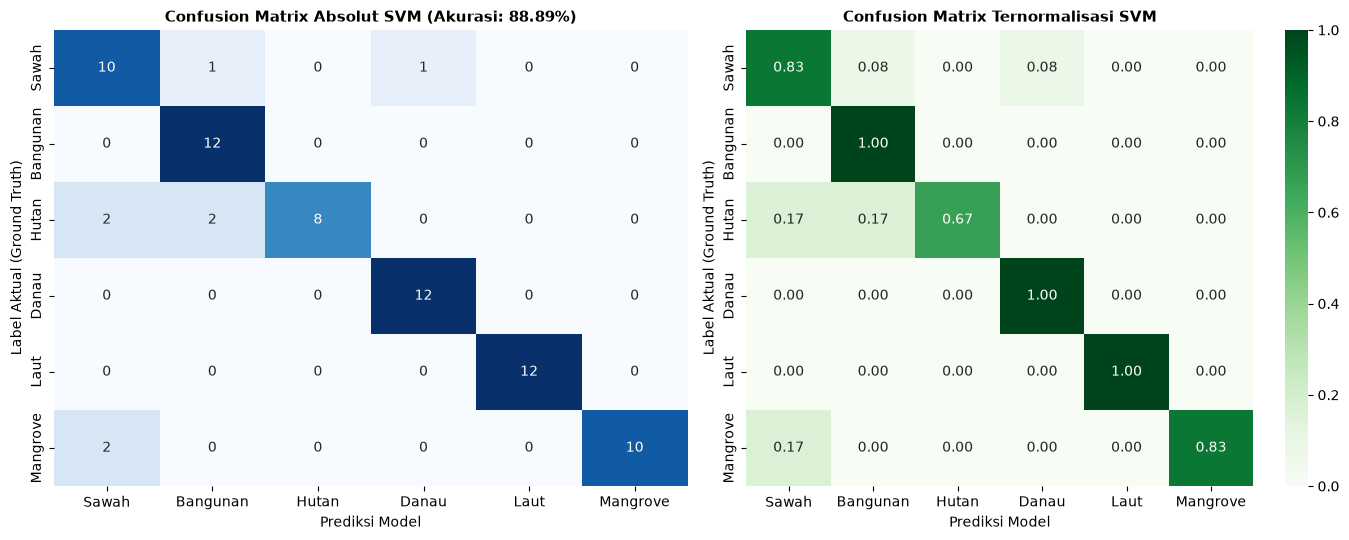

Grafik confusion matrix tersimpan di: D:\tugas psd\website-jupyterbook\UTS\output\04_confusion_matrix_svm.png


In [5]:
cm = confusion_matrix(y_test, y_test_pred, labels=[1, 2, 3, 4, 5, 6])
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names, ax=ax1, cbar=False)
ax1.set_title(f'Confusion Matrix Absolut SVM (Akurasi: {acc_test:.2f}%)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Prediksi Model', fontsize=10)
ax1.set_ylabel('Label Aktual (Ground Truth)', fontsize=10)

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens', xticklabels=label_names, yticklabels=label_names, ax=ax2)
ax2.set_title('Confusion Matrix Ternormalisasi SVM', fontsize=11, fontweight='bold')
ax2.set_xlabel('Prediksi Model', fontsize=10)
ax2.set_ylabel('Label Aktual (Ground Truth)', fontsize=10)

plt.tight_layout()
berkas_cm = OUT_DIR / "04_confusion_matrix_svm.png"
plt.savefig(berkas_cm, dpi=200)
plt.show()
print(f"Grafik confusion matrix tersimpan di: {berkas_cm}")

### 5. Menyimpan Hasil Prediksi Seluruh Poligon
Menambahkan kolom `pred_svm`, `pred_svm_teks`, dan `benar` ke dalam dataframe poligon, lalu mengekspor ke `output/df_poligon_pred_svm.csv`.

In [6]:
label_map = {1: 'Sawah', 2: 'Bangunan', 3: 'Hutan', 4: 'Danau', 5: 'Laut', 6: 'Mangrove'}

# Prediksi untuk seluruh 357 poligon
X_all = df_poligon[FITUR_SPEKTRAL]
df_poligon['pred_svm'] = model_pipeline.predict(X_all)
df_poligon['pred_svm_teks'] = df_poligon['pred_svm'].map(label_map)
df_poligon['benar'] = (df_poligon['label'] == df_poligon['pred_svm'])

# Probabilitas prediksi (confidence)
proba = model_pipeline.predict_proba(X_all)
df_poligon['confidence'] = proba.max(axis=1)

berkas_pred = OUT_DIR / "df_poligon_pred_svm.csv"
df_poligon.to_csv(berkas_pred, index=False)
print(f"Data prediksi poligon tersimpan di: {berkas_pred.resolve()}")

# Evaluasi subset data uji
uji_benar = df_poligon[df_poligon['split'] == 'Test']['benar'].value_counts()
print("\nRingkasan Prediksi Data Uji (72 poligon):")
print(uji_benar)

print("\n=== DAFTAR BERKAS KELUARAN NOTEBOOK 04 ===")
for f in [berkas_model, berkas_pred, berkas_cm, OUT_DIR / "04_classification_report.txt"]:
    print(f"- {f.name} ({f.stat().st_size:,} bytes)")

Data prediksi poligon tersimpan di: D:\tugas psd\website-jupyterbook\UTS\output\df_poligon_pred_svm.csv

Ringkasan Prediksi Data Uji (72 poligon):
benar
True     64
False     8
Name: count, dtype: int64

=== DAFTAR BERKAS KELUARAN NOTEBOOK 04 ===
- model_svm.joblib (28,421 bytes)
- df_poligon_pred_svm.csv (93,182 bytes)
- 04_confusion_matrix_svm.png (151,250 bytes)
- 04_classification_report.txt (554 bytes)
